INF201- Deliverable 2
Submited by: Kiran Giri, Sanjok Mahat, Durga Bahadur Karki
Github Link: https://github.com/pirategiri/INF201-Deliverable2


In [17]:
import json
import re
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
OUT_DIR = Path("output")

STATUSES = ["SUCCESS", "REFUND", "CANCELLED"]

Task 1: 

In [5]:
"""Task 1: Reading log files and parsing them."""
import re
from pathlib import Path


def read_file(path : str) -> tuple[str, str]:
    """Read a text file. Try UTF-8 first, then fall back to Latin-1.
    """
    path = Path(path)
    raw = path.read_bytes()
    try:
        return raw.decode("utf-8"), "utf-8"
    except UnicodeDecodeError:
        # Latin-1 accepts every byte, so it must be the fallback, not the first try
        return raw.decode("iso-8859-1"), "iso-8859-1"


LINE_PATTERN = re.compile(
    r"\[(?P<timestamp>\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\] "
    r"\[(?P<register_id>\w+)\] "
    r"item=(?P<item>.+?) "
    r"price=(?P<price>\d+\.\d+) "
    r"(?P<currency>[A-Z]{3}) "
    r"\((?P<status>SUCCESS|REFUND|CANCELLED)\)"
)


def parse_log(text : str) -> list[dict]:
    """Return a list of dicts, one per valid sales line. Noise lines are skipped."""
    records = []
    for line in text.splitlines():
        match = LINE_PATTERN.fullmatch(line.strip())
        if match:
            record = match.groupdict()
            record["price"] = float(record["price"])
            records.append(record)
    return records

Task 1 Test Code

In [6]:
# 1) one real file: expect 80 records
sample_file = DATA_DIR / "2026" / "library_cafe" / "POS_01" / "register_sales.log"
text, encoding = read_file(sample_file)
records_one = parse_log(text)
print("encoding:", encoding, "| records:", len(records_one))
print(records_one[:2])

# 2) the Latin-1 fallback (our generated files are plain ASCII, so we make a test file)
with tempfile.TemporaryDirectory() as tmp:
    test_file = Path(tmp) / "latin.txt"
    test_file.write_bytes("Caf\u00e9".encode("iso-8859-1"))
    print(read_file(test_file))

# 3) noise lines must be ignored
print(parse_log("[DEBUG] BARCODE SCANNER REBOOTED\n=== NETWORK SYNC OK ==="))

encoding: utf-8 | records: 80
[{'timestamp': '2026-10-15 07:02:45', 'register_id': 'POS_01', 'item': 'Sandwich', 'price': 7.53, 'currency': 'EUR', 'status': 'SUCCESS'}, {'timestamp': '2026-10-15 07:05:10', 'register_id': 'POS_01', 'item': 'Muffin', 'price': 3.08, 'currency': 'NOK', 'status': 'SUCCESS'}]
('Café', 'iso-8859-1')
[]


Task 2: Recursive Function
Find_log_files : This is a recursive function that looks at every item in a folder and if it is a .log file, it adds to the list. A folder with no subfolder ends the recursion automatically

Find_Active_Register: This recursive function works for the config file. For a dict it checks active values and recurses back to it. For a list it recuses into each element. 


In [8]:
def find_log_files(folder):
    """Return a list of Path objects for all .log files in folder and its subfolders."""
    folder = Path(folder)
    found = []
    for item in folder.iterdir():
        if item.is_dir():
            found.extend(find_log_files(item))  # go deeper
        elif item.is_file() and item.suffix == ".log":
            found.append(item)
    return found


def find_active_registers(data):
    """Return the set of register ids where "active" is true.

    Works on any mix of nested dicts and lists.
    """
    active = set()
    if isinstance(data, dict):
        if data.get("active") is True and "id" in data:
            active.add(data["id"])
        for value in data.values():
            active |= find_active_registers(value)
    elif isinstance(data, list):
        for element in data:
            active |= find_active_registers(element)
    return active

Test for recursion

In [9]:
log_files = find_log_files(DATA_DIR / "2026")
print(len(log_files), "log files found")
for f in sorted(log_files)[:3]:
    print(" ", f)

# the example config from the assignment text
example = {"company": "Campus Coffee", "regions": [{"region_name": "Main Campus", "stores": [
    {"name": "Library Cafe", "registers": [{"id": "POS_01", "active": True},
                                           {"id": "POS_02", "active": False}]}]}]}
print("example:", find_active_registers(example))

config = json.loads((DATA_DIR / "store_config.json").read_text(encoding="utf-8"))
active_registers = find_active_registers(config)
print("real config:", sorted(active_registers))

9 log files found
  data/2026/library_cafe/POS_01/register_sales.log
  data/2026/library_cafe/POS_02/register_sales.log
  data/2026/library_cafe/POS_03/register_sales.log
example: {'POS_01'}
real config: ['POS_01', 'POS_02', 'POS_03']


Task 3: Analysis of the data using numpy

In [10]:
def remove_outliers(prices):
    """Replace values more than 3 standard deviations from the mean with the median."""
    prices = np.array(prices, dtype=float)  # np.array makes a copy
    mean = prices.mean()
    std = prices.std()
    is_outlier = np.abs(prices - mean) > 3 * std
    median = np.median(prices[~is_outlier])
    prices[is_outlier] = median
    return prices


def compute_refund_ratio(sales_count, refund_count):
    """Element-wise refund ratio. The tiny 1e-6 avoids division by zero."""
    return refund_count / (sales_count + 1e-6)

The small number 1e-6 is added to the sales count so we never divide by zero. If an item has no sales, the ratio becomes 0 instead of crashing the code. The number is so small that it doesn’t change the real ratios.

Task 4: Data handling and cleaning with pandas

In [11]:
def build_dataframe(records :list[dict]) -> pd.DataFrame:
    """List of dicts -> DataFrame indexed by timestamp, sorted in time order."""
    df = pd.DataFrame(records)
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.set_index("timestamp").sort_index()
    return df


def hourly_revenue(df:pd.DataFrame) -> pd.Series:
    """Total price per item in 1-hour windows."""
    return df.groupby("item")["price"].resample("1h").sum()


def status_pivot(df):
    """Total revenue per item (rows) and status (columns)."""
    pivot = df.pivot_table(values="price", index="item", columns="status",
                           aggfunc="sum", fill_value=0)
    return pivot.reindex(columns=STATUSES, fill_value=0)


def item_refund_ratios(df:pd.DataFrame) -> pd.DataFrame:
    """Refund ratio per item. Sales count = number of SUCCESS transactions."""
    counts = df.groupby(["item", "status"]).size().unstack(fill_value=0)
    counts = counts.reindex(columns=STATUSES, fill_value=0)
    ratio = compute_refund_ratio(counts["SUCCESS"].to_numpy(),
                                 counts["REFUND"].to_numpy())
    return pd.DataFrame({"item": counts.index, "refund_ratio": ratio})

Test task 3

In [12]:
tiny = [
    {"timestamp": "2026-10-15 08:10:00", "register_id": "POS_01", "item": "Latte", "price": 4.0, "currency": "EUR", "status": "SUCCESS"},
    {"timestamp": "2026-10-15 08:40:00", "register_id": "POS_01", "item": "Latte", "price": 5.0, "currency": "EUR", "status": "SUCCESS"},
    {"timestamp": "2026-10-15 09:05:00", "register_id": "POS_02", "item": "Latte", "price": 4.5, "currency": "EUR", "status": "REFUND"},
    {"timestamp": "2026-10-15 07:30:00", "register_id": "POS_02", "item": "Muffin", "price": 3.5, "currency": "EUR", "status": "SUCCESS"},
]
tiny_df = build_dataframe(tiny)
print(tiny_df.index.is_monotonic_increasing)
print(hourly_revenue(tiny_df))
print(status_pivot(tiny_df))
print(item_refund_ratios(tiny_df))

True
item    timestamp          
Latte   2026-10-15 08:00:00    9.0
        2026-10-15 09:00:00    4.5
Muffin  2026-10-15 07:00:00    3.5
Name: price, dtype: float64
status  SUCCESS  REFUND  CANCELLED
item                              
Latte       9.0     4.5          0
Muffin      3.5     0.0          0
     item  refund_ratio
0   Latte           0.5
1  Muffin           0.0


Task 5 : Full workflow

In [ ]:
pivot

In [ ]:
def run_workflow():
    # 1. find log files and active register ids
    log_files = find_log_files(DATA_DIR / "2026")
    config = json.loads((DATA_DIR / "store_config.json").read_text(encoding="utf-8"))
    active = find_active_registers(config)
    print(f"1. {len(log_files)} log files, active registers: {sorted(active)}")

    # 2. read and parse all files
    records = []
    for file in sorted(log_files):
        text, encoding = read_file(file)
        file_records = parse_log(text)
        print(f"   {file.parent.parent.name}/{file.parent.name}: {len(file_records)} records ({encoding})")
        records.extend(file_records)
    n_before = len(records)
    records = [r for r in records if r["register_id"] in active]
    print(f"2. {n_before} records parsed, {n_before - len(records)} dropped (inactive registers)")

    # 3. dataframe
    df = build_dataframe(records)
    print(f"3. DataFrame shape: {df.shape}")

    # 4. remove price outliers
    old_prices = df["price"].to_numpy()
    new_prices = remove_outliers(old_prices)
    print(f"4. outliers replaced: {(old_prices != new_prices).sum()} | max price {old_prices.max():.2f} -> {new_prices.max():.2f}")
    df["price"] = new_prices

    # 5. NOK correction
    is_nok = df["currency"] == "NOK"
    before = df.loc[is_nok, "price"].mean()
    df.loc[is_nok, "price"] *= 10.0
    print(f"5. NOK mean price {before:.2f} -> {df.loc[is_nok, 'price'].mean():.2f}")

    # 6. reports
    hourly = hourly_revenue(df)
    pivot = status_pivot(df)
    ratios = item_refund_ratios(df)
    print("6. reports created")

    # 7. save the four output files
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUT_DIR / "cleaned_transactions.csv")
    hourly_dict = {}
    for (item, hour), total in hourly.items():
        hourly_dict.setdefault(item, {})[str(hour)] = float(total)
    with open(OUT_DIR / "hourly_revenue.json", "w", encoding="utf-8") as f:
        json.dump(hourly_dict, f, indent=2)
    pivot.to_csv(OUT_DIR / "status_pivot_table.csv")
    ratios.to_csv(OUT_DIR / "item_refund_ratios.csv", index=False)
    print("7. files saved in", OUT_DIR)

    return df, hourly, pivot, ratios


df, hourly, pivot, ratios = run_workflow()

1. 9 log files, active registers: ['POS_01', 'POS_02', 'POS_03']
   library_cafe/POS_01: 80 records (utf-8)
   library_cafe/POS_02: 80 records (utf-8)
   library_cafe/POS_03: 80 records (utf-8)
   science_building/POS_01: 80 records (utf-8)
   science_building/POS_02: 80 records (utf-8)
   science_building/POS_03: 80 records (utf-8)
   student_union/POS_01: 80 records (utf-8)
   student_union/POS_02: 80 records (utf-8)
   student_union/POS_03: 80 records (utf-8)
2. 720 records parsed, 0 dropped (inactive registers)
3. DataFrame shape: (720, 5)
4. outliers replaced: 20 | max price 999.00 -> 7.99
5. NOK mean price 4.57 -> 45.71
6. reports created
7. files saved in output


Dicussion Task 5:


Plots and Visualization

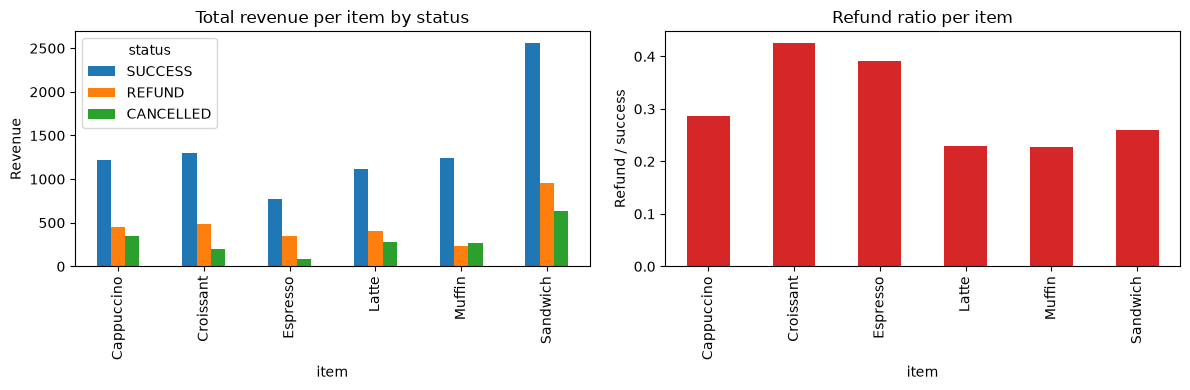

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pivot.plot(kind="bar", ax=axes[0])
axes[0].set_title("Total revenue per item by status")
axes[0].set_ylabel("Revenue")
ratios.set_index("item")["refund_ratio"].plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set_title("Refund ratio per item")
axes[1].set_ylabel("Refund / success")
plt.tight_layout()
plt.show()

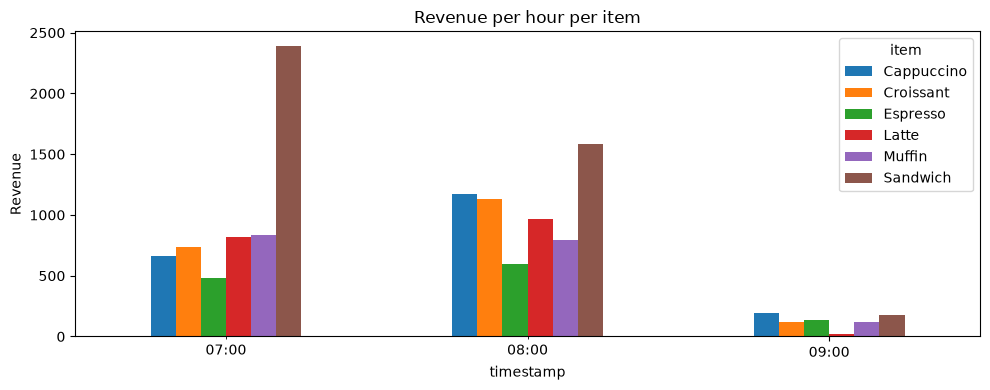

In [20]:
hourly.unstack(level=0).plot(kind="bar", figsize=(10, 4), title="Revenue per hour per item")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Output Files

In [ ]:
for f in sorted(OUT_DIR.iterdir()):
    print(f.name, "-", f.stat().st_size, "bytes")
pd.read_csv(OUT_DIR / "cleaned_transactions.csv").head()

Task 1: File ingestion and regular expressions — Discussion

In this task, we focused on reading transaction logs with different encodings and extracting useful information. Since the log files contain both valid transactions and unwanted system messages, we needed to separate them. We kept only the valid transaction records and ignored unnecessary lines. This helped us prepare the transaction data for further processing.

Task 2: Recursive utility functions — Discussion

In this task, we focused on finding log files stored in different folders and subfolders. We used recursion to search through the complete folder structure. We also searched through the store configuration data to identify active registers. This helped us find the required files and select transactions from active registers only.

Task 3: Functions for cleaning and analysing data using NumPy — Discussion

In this task, we focused on cleaning incorrect price values and calculating refund ratios. Some transactions contained unusually high prices caused by system errors. We identified these unusual values and replaced them with the median of valid prices. We also calculated refund ratios by comparing refunds with successful sales. This helped us improve data quality and understand refund activity.

Task 5: Create full workflow — Discussion

In this task, we combined all the previous tasks into one complete workflow. We collected transaction records from log files and kept only those from active registers. We cleaned unusual prices and corrected NOK prices by multiplying them by 10. After cleaning the data, we calculated hourly revenue, transaction totals by status, and refund ratios. Finally, we saved the cleaned transactions and analysis results into four output files. This allowed us to complete the entire process automatically.

Final Summary

In this assignment, we developed a complete data processing workflow for the Campus Coffee Shop Sales Pipeline. We used Python to collect transaction data from different log files, remove unwanted information, and organize the valid records. We also identified active registers, cleaned unusual prices, and corrected NOK prices.

After cleaning the data, we used NumPy and Pandas to analyze hourly revenue, transaction statuses, and refund ratios for different items. We also created plots to visualize the results and make them easier to understand.

Finally, we generated four output files containing the cleaned transactions and analysis reports. Overall, this assignment helped us understand how file handling, recursion, regular expressions, NumPy, and Pandas can be combined to process and analyze real-world transaction data automatically.